Fetcheing user/customer data from a given API endpoint.
    Args:
        url (str): The API endpoint URL string.
    Returns:
        list: A list of dictionaries containing customer details.


In [15]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

API_URL = "https://jsonplaceholder.typicode.com/users"


In [16]:
def get_customers(url: str = API_URL) -> list[dict]:
    """Fetch the customer list. Report failures clearly instead of crashing."""
    try:
        response = requests.get(url, timeout=10)   
        response.raise_for_status()                
        return response.json()                     
    except requests.exceptions.RequestException as e:
        print(f"Could not fetch customer data: {e}")
        return []

customers = get_customers("https://jsonplaceholder.typicode.com/users")
print(len(customers))

10


In [17]:
customers

[{'id': 1,
  'name': 'Leanne Graham',
  'username': 'Bret',
  'email': 'Sincere@april.biz',
  'address': {'street': 'Kulas Light',
   'suite': 'Apt. 556',
   'city': 'Gwenborough',
   'zipcode': '92998-3874',
   'geo': {'lat': '-37.3159', 'lng': '81.1496'}},
  'phone': '1-770-736-8031 x56442',
  'website': 'hildegard.org',
  'company': {'name': 'Romaguera-Crona',
   'catchPhrase': 'Multi-layered client-server neural-net',
   'bs': 'harness real-time e-markets'}},
 {'id': 2,
  'name': 'Ervin Howell',
  'username': 'Antonette',
  'email': 'Shanna@melissa.tv',
  'address': {'street': 'Victor Plains',
   'suite': 'Suite 879',
   'city': 'Wisokyburgh',
   'zipcode': '90566-7771',
   'geo': {'lat': '-43.9509', 'lng': '-34.4618'}},
  'phone': '010-692-6593 x09125',
  'website': 'anastasia.net',
  'company': {'name': 'Deckow-Crist',
   'catchPhrase': 'Proactive didactic contingency',
   'bs': 'synergize scalable supply-chains'}},
 {'id': 3,
  'name': 'Clementine Bauch',
  'username': 'Samantha

In [18]:
def explore(record: dict, indent: int = 0) -> None:
    """Print every key in a (possibly nested) record with its type, indented by depth."""
    for key, value in record.items():
        print("  " * indent + key + ": " + type(value).__name__)
        if isinstance(value, dict):
            explore(value, indent + 1)

explore(customers[0])

id: int
name: str
username: str
email: str
address: dict
  street: str
  suite: str
  city: str
  zipcode: str
  geo: dict
    lat: str
    lng: str
phone: str
website: str
company: dict
  name: str
  catchPhrase: str
  bs: str


In [19]:
def extract_attributes(customers: list[dict]) -> list[dict]:
    """Return one flat dict per customer with the attributes listed in the task."""
    results = []
    for c in customers:
        flat = {
            "id": c["id"],
            "name": c["name"],
            "username": c["username"],
            "email": c["email"],
            "email_domain": c["email"].split("@")[1],
            "phone": c["phone"],
            "city": c["address"]["city"],
            "zipcode": c["address"]["zipcode"],
            "latitude": float(c["address"]["geo"]["lat"]),
            "longitude": float(c["address"]["geo"]["lng"]),
            "company": c["company"]["name"],
            "website": c["website"],
        }
        results.append(flat)
    return results

In [20]:
customers = get_customers()
flat = extract_attributes(customers)
print(len(flat))                   
print(flat[0])                      
print(type(flat[0]["latitude"]))   

10
{'id': 1, 'name': 'Leanne Graham', 'username': 'Bret', 'email': 'Sincere@april.biz', 'email_domain': 'april.biz', 'phone': '1-770-736-8031 x56442', 'city': 'Gwenborough', 'zipcode': '92998-3874', 'latitude': -37.3159, 'longitude': 81.1496, 'company': 'Romaguera-Crona', 'website': 'hildegard.org'}
<class 'float'>


In [37]:
def unique_cities(customers: list[dict]) -> set[str]:
    """Return the set of distinct cities."""
    return {c["address"]["city"] for c in customers}

In [38]:
def city_counts(customers: list[dict]) -> dict[str, int]:
    """Count customers per city using a loop (no Counter, no pandas)."""
    counts = {}
    for c in customers:
        city = c["address"]["city"]
        counts[city] = counts.get(city, 0) + 1
    return counts

In [39]:
def email_domain_counts(customers: list[dict]) -> dict[str, int]:
    """Count customers per email top-level domain (e.g. 'biz', 'tv')."""
    tlds = [c["email"].split("@")[1].split(".")[-1] for c in customers]
    return {tld: tlds.count(tld) for tld in set(tlds)}


In [40]:
def to_dataframe(rows: list[dict]) -> pd.DataFrame:
    """Turn the list of flat dicts into a DataFrame."""
    return pd.DataFrame(rows)


In [41]:
def plot_distribution(counts: dict[str, int], title: str = "Customers per city") -> None:
    """Display a labelled bar chart of the distribution."""
    ordered = sorted(counts.items(), key=lambda item: item[1], reverse=True)
    labels = [k for k, _ in ordered]
    values = [v for _, v in ordered]

    plt.figure(figsize=(9, 5))
    plt.bar(labels, values)
    plt.title(title)
    plt.xlabel("Category")
    plt.ylabel("Number of customers")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(range(0, max(values) + 1))
    plt.tight_layout()
    plt.show()

In [42]:


def print_sorted(counts: dict[str, int]) -> None:
    """Print a count dict from most to least common."""
    for key, n in sorted(counts.items(), key=lambda item: item[1], reverse=True):
        print(f"  {key}: {n}")




Customers fetched: 10

--- Step 2: structure of one record ---
id: int
name: str
username: str
email: str
address: dict
  street: str
  suite: str
  city: str
  zipcode: str
  geo: dict
    lat: str
    lng: str
phone: str
website: str
company: dict
  name: str
  catchPhrase: str
  bs: str

--- Step 3: flat attributes ---
{'id': 1, 'name': 'Leanne Graham', 'username': 'Bret', 'email': 'Sincere@april.biz', 'email_domain': 'april.biz', 'phone': '1-770-736-8031 x56442', 'city': 'Gwenborough', 'zipcode': '92998-3874', 'latitude': -37.3159, 'longitude': 81.1496, 'company': 'Romaguera-Crona', 'website': 'hildegard.org'}
<class 'float'>

--- Step 4: unique cities ---
Unique cities: 10 | Customers: 10

--- Step 5: counts ---
Customers per city:
  Gwenborough: 1
  Wisokyburgh: 1
  McKenziehaven: 1
  South Elvis: 1
  Roscoeview: 1
  South Christy: 1
  Howemouth: 1
  Aliyaview: 1
  Bartholomebury: 1
  Lebsackbury: 1
Customers per email domain (TLD):
  biz: 3
  io: 1
  me: 1
  tv: 1
  net: 1
  inf

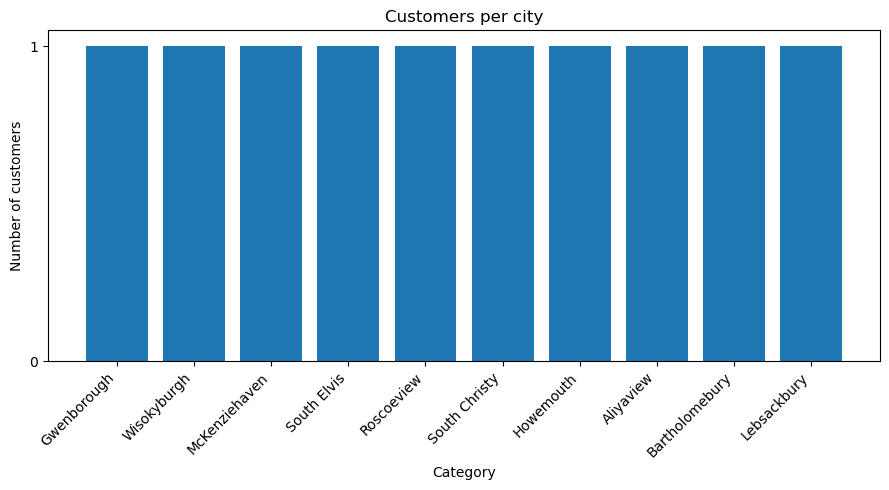

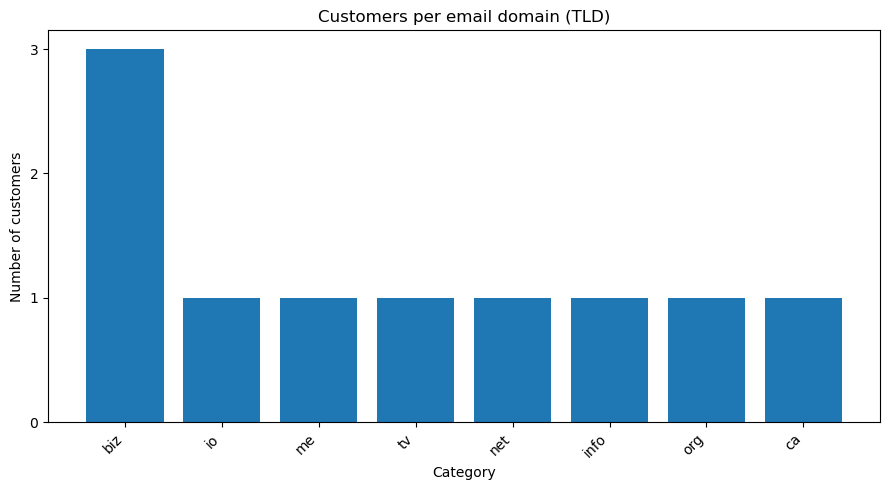

In [ ]:
if __name__ == "__main__":
    customers = get_customers()
    print("Customers fetched:", len(customers))

    print("\n--- Step 2: structure of one record ---")
    explore(customers[0])

    print("\n--- Step 3: flat attributes ---")
    flat = extract_attributes(customers)
    print(flat[0])
    print(type(flat[0]["latitude"]))

    print("\n--- Step 4: unique cities ---")
    cities = unique_cities(customers)
    print("Unique cities:", len(cities), "| Customers:", len(customers))

    print("\n--- Step 5: counts ---")
    print("Customers per city:")
    print_sorted(city_counts(customers))
    print("Customers per email domain (TLD):")
    print_sorted(email_domain_counts(customers))

    print("\n--- Step 6: DataFrame ---")
    df = to_dataframe(flat)
    print("Shape:", df.shape)
    print(df.dtypes)

    
    pandas_city = df["city"].value_counts().to_dict()
    pandas_tld = df["email_domain"].str.split(".").str[-1].value_counts().to_dict()
    print("City counts match:", pandas_city == city_counts(customers))
    print("Email TLD counts match:", pandas_tld == email_domain_counts(customers))

    print("\n--- Step 7: export CSV ---")
    df.to_csv("customers.csv", index=False)
    city_df = pd.DataFrame(
        sorted(city_counts(customers).items(), key=lambda item: item[1], reverse=True),
        columns=["city", "customers"],
    )
    city_df.to_csv("city_counts.csv", index=False)
    print("Saved customers.csv and city_counts.csv")

    print("\n--- Step 8: charts ---")
    plot_distribution(city_counts(customers), "Customers per city")
    plot_distribution(email_domain_counts(customers), "Customers per email domain (TLD)")